# code_017 · Parameters, predictions and objectives

**Book:** Chapter 4, section 4.1. **Scope:** an inspectable learning-mechanism laboratory with locally generated data. These examples do not establish real structural safety, causal effects, generalization to new materials or a competitive model benchmark. They are not exhaustive estimator-constructor studies.

Use the [quickstart](../README.md) and [pinned environment](../requirements-lock.txt). Restart the kernel and run every cell in order. Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, scikit-learn 1.9.0, CPU only on macOS ARM64. All data/helpers/imports are inside this notebook. No ordinary-run files, network downloads, credentials, GPU or private imports are needed. Allow a minute to execute and 30–60 minutes to inspect predictions and exercises. Actual timing, versions and results appear at the end and in [execution evidence](../CHAPTER_04_EXECUTION.md).

Read each prediction prompt first. Parameter values, fitted state, model/training controls, sampling assumptions and decision criteria have different roles. The [traceability guide](../CHAPTER_04_GUIDE.md) maps these mechanisms and exercises; the [stable registry](../CODE_EXAMPLES.md#code_017) preserves this ID. Every fitted assessment example declares its information boundary; pure gradient and failure checks use constructed training data only.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from scipy import special
from IPython.display import display
START=time.perf_counter();SEED=417;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,
'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,
'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 417


<a id="contract"></a>
## Load-to-measured-deflection contract

Each synthetic row is one independent member, not a repeated reading from a hidden shared building. Load P is known at prediction time, response y is measured deflection in mm. The observation generator is y=1.8*(P/1000)+.15+noise, noise sd .1 mm. The intercept is an illustrative measurement offset, not a claim about unloaded equilibrium. Features are (P/1000,1), with both coefficients in mm. A fixed permutation allocates 144 training, 48 development and 48 final members before fitting; no hyperparameter or seed search is performed.

**Predict:** what are the units of the fitted coefficients and the slope with respect to P? Why would repeated buildings require a different split contract?


In [2]:
N=240;member_id=np.arange(N);load_N=rng.uniform(100,1000,N);x=load_N/1000.
y_mm=1.8*x+.15+rng.normal(0,.1,N);X=np.column_stack([x,np.ones(N)])
permutation=rng.permutation(N);train=permutation[:144];development=permutation[144:192];final=permutation[192:]
assert not set(train)&set(development) and not set(train)&set(final) and not set(development)&set(final)
assert len(set(np.r_[train,development,final]))==N and X.shape==(N,2)
ledger=pd.DataFrame([
 ['a,b','trainable parameters','mm','least squares on training labels'],
 ['P_ref=1000','declared unit reference','N','chosen before fit'],
 ['affine family','model choice','rule','fixed before assessment'],
 ['split permutation/seed','reproducibility control','indices','fixed before fit'],
 ['feature order/units','stored schema','metadata','required with coefficients'],
 ['y_hat','prediction','mm','changes with input at fixed parameters']
],columns=['quantity','role','units','provenance']);display(ledger)


,quantity,role,units,provenance
0,"a,b",trainable parameters,mm,least squares on training labels
1,P_ref=1000,declared unit reference,N,chosen before fit
2,affine family,model choice,rule,fixed before assessment
3,split permutation/seed,reproducibility control,indices,fixed before fit
4,feature order/units,stored schema,metadata,required with coefficients
5,y_hat,prediction,mm,changes with input at fixed parameters


<a id="fit"></a>
## An empirical objective and its independent reference fit

R=.5*mean((X@theta-y)²) has units mm². The constant baseline is the training-target mean. Fit by least squares; an optimizer loop is not needed for this tiny convex problem. The residual gradient X.T@(X@theta-y)/n should vanish at the unpenalized optimum. This is an implementation check, not evidence of future performance.

**Predict:** is a training mean baseline allowed to inspect development targets? Does adding a slope penalty supply extra observations or change the problem?


In [3]:
def risk(X,y,theta):
 residual=X@theta-y
 assert residual.shape==y.shape
 return .5*np.mean(residual**2)
theta=np.linalg.lstsq(X[train],y_mm[train],rcond=None)[0]
gradient=X[train].T@(X[train]@theta-y_mm[train])/len(train)
baseline=float(y_mm[train].mean())
assert np.linalg.norm(gradient)<1e-12
assert risk(X[train],y_mm[train],theta)<=.5*np.mean((baseline-y_mm[train])**2)
print('theta [mm]:',theta,'slope [mm/N]:',theta[0]/1000,'gradient norm [mm]:',np.linalg.norm(gradient))
RESULTS['coefficients_mm']=theta.tolist();RESULTS['training_half_MSE_mm2']=float(risk(X[train],y_mm[train],theta));RESULTS['gradient_norm_mm']=float(np.linalg.norm(gradient))


theta [mm]: [1.75746797 0.17443713] slope [mm/N]: 0.001757467973123193 gradient norm [mm]: 1.298494423624216e-16


<a id="development"></a>
## Read the fitted rule before final assessment

The plot and development diagnostic inspect the fixed model; nothing is retuned. A production artifact also needs feature meanings/order and any fitted preprocessing. There is no scaler here: dividing by a fixed reference load is a declared unit transformation, not learned preprocessing or pretraining.

**Predict:** if the reference load changes to 500 N, what coefficient change preserves the same physical line? What happens to an unadjusted coefficient penalty?


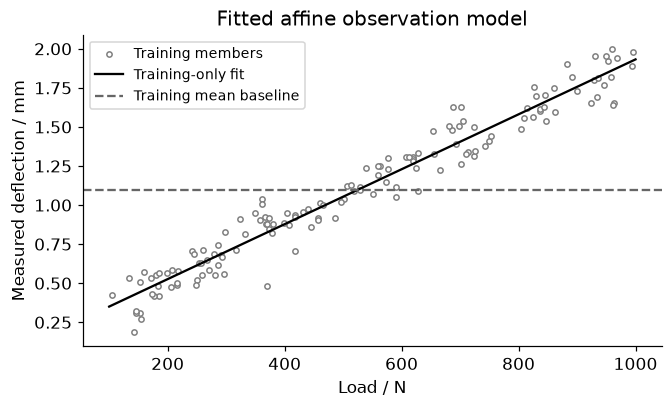

Development MAE [mm]: 0.0693926217087345


In [4]:
line=np.linspace(100,1000,150);line_X=np.column_stack([line/1000,np.ones(len(line))])
fig,ax=plt.subplots(figsize=(6,3.6));ax.scatter(load_N[train],y_mm[train],s=12,facecolors='white',edgecolors='.5',label='Training members')
ax.plot(line,line_X@theta,'k-',label='Training-only fit');ax.axhline(baseline,color='.4',ls='--',label='Training mean baseline')
ax.set(xlabel='Load / N',ylabel='Measured deflection / mm',title='Fitted affine observation model');ax.legend(fontsize=9);plt.show()
print('Development MAE [mm]:',np.mean(abs(X[development]@theta-y_mm[development])))
new_feature=np.column_stack([load_N/500,np.ones(N)]);new_theta=np.array([theta[0]/2,theta[1]])
assert np.allclose(new_feature@new_theta,X@theta)


<a id="final"></a>
## Final assessment after the rule is fixed

Open final outcomes once for this fixed illustrative model and metric. Their score is synthetic and not tuned into a new model choice. After reading the final result, extensions need fresh assessment evidence.


In [5]:
final_prediction=X[final]@theta
mae=float(np.mean(abs(final_prediction-y_mm[final])));baseline_mae=float(np.mean(abs(baseline-y_mm[final])))
assert final_prediction.shape==(48,) and np.isfinite(mae)
print('Final MAE [mm]:',mae,'training-mean baseline MAE [mm]:',baseline_mae)
RESULTS['final_MAE_mm']=mae;RESULTS['baseline_final_MAE_mm']=baseline_mae


Final MAE [mm]: 0.08834512346320854 training-mean baseline MAE [mm]: 0.4504293753807134


<a id="one-step"></a>
## Predict, compare, adjust on one separate observation

Dimensionless features (1,2), weights (.1,.2) mm and target 1 mm give prediction .5 mm. For half squared error, gradient is (prediction-target)*features. Rate .1 yields weights (.15,.3), prediction .75 and loss .03125 mm². This separate hand check is not a second use of the final assessment.


In [6]:
features=np.array([1.,2.]);weights=np.array([.1,.2]);target=1.;eta=.1
prediction=features@weights;loss=.5*(prediction-target)**2;g=(prediction-target)*features
updated=weights-eta*g;prediction_after=features@updated;loss_after=.5*(prediction_after-target)**2
assert np.isclose(prediction,.5) and np.allclose(g,[-.5,-1.])
assert np.allclose(updated,[.15,.3]) and np.isclose(loss_after,.03125) and target==1.
print({'prediction_before_mm':prediction,'loss_before_mm2':loss,'weights_after_mm':updated.tolist(),'prediction_after_mm':prediction_after,'loss_after_mm2':loss_after})
RESULTS['one_step_loss_before_after_mm2']=[float(loss),float(loss_after)]


{'prediction_before_mm': np.float64(0.5), 'loss_before_mm2': np.float64(0.125), 'weights_after_mm': [0.15000000000000002, 0.30000000000000004], 'prediction_after_mm': np.float64(0.7500000000000001), 'loss_after_mm2': np.float64(0.031249999999999972)}


<a id="exercises"></a>
## Exercises and hints

1. Convert measured y from mm to m. Track coefficient, gradient and loss units and compare the physical predictions.
2. Remove the intercept only if the target truly obeys zero response at zero load. Test an offset measurement model separately.
3. Derive the gradient of R+lambda*a²/2 and state which coefficient is penalized. Explain why rescaling x changes an unadjusted penalty.
4. List the extra state needed to resume a momentum-based training loop compared with making a prediction.
5. Adapt to repeated sensors in buildings, specifying split and averaging units before fitting. Preserve fresh final evidence.

**Hints:** a prediction is an evaluated value, parameters define the rule, and fitted feature statistics are state even without gradients. More coefficients do not automatically mean a better task specification.

**Troubleshooting:** validate IDs/shapes/units before the solver. [NumPy least squares](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html) documents the reference solve; [scikit-learn linear models](https://scikit-learn.org/1.9/modules/linear_model.html) develops later estimator families. This notebook is a scoped mechanism lab.


In [7]:
summary={'example_id':'code_017','seed':SEED,'versions':VERSIONS,
'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['task and independent split contract', 'parameter hyperparameter state ledger', 'unit-aware empirical risk', 'training-only least squares and baseline', 'gradient stationarity', 'one-example predict compare adjust'],
'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["task and independent split contract", "parameter hyperparameter state ledger", "unit-aware empirical risk", "training-only least squares and baseline", "gradient stationarity", "one-example predict compare adjust"], "elapsed_seconds": 0.1, "example_id": "code_017", "hardware": "Darwin arm64 CPU", "results": {"baseline_final_MAE_mm": 0.4504293753807134, "coefficients_mm": [1.757467973123193, 0.1744371289769928], "final_MAE_mm": 0.08834512346320854, "gradient_norm_mm": 1.298494423624216e-16, "one_step_loss_before_after_mm2": [0.125, 0.031249999999999972], "training_half_MSE_mm2": 0.005047060348352905}, "seed": 417, "versions": {"matplotlib": "3.11.0", "numpy": "2.4.4", "pandas": "3.0.3", "python": "3.14.3", "scikit-learn": "1.9.0", "scipy": "1.17.1"}}
